# Exploratory Data Analysis (EDA)
## Dysgraphia Handwriting Classification Dataset

Notebook ini difokuskan khusus untuk melakukan **Exploratory Data Analysis (EDA)** tahap awal pada dataset klasifikasi tulisan tangan anak dengan dua kelas:
* **`Low Potential Dysgraphia`** (Potensi Rendah Disgrafia)
* **`Potential Dysgraphia`** (Potensi Disgrafia)

---

### 🎯 Tujuan Analisis
1. **Memahami Struktur & Direktori**: Membaca dataset dan mengidentifikasi sebaran data pada tiap folder kelas.
2. **Validasi Kualitas Data**: Mengecek integritas file citra (gambar rusak/corrupt, file non-gambar, folder kosong).
3. **Analisis Distribusi Kelas**: Mengamati keseimbangan data (*class balance vs class imbalance*).
4. **Visualisasi Sampel Citra**: Menampilkan contoh visual tulisan tangan dari masing-masing kelas secara acak dan reproducible.
5. **Analisis Properti Citra**: Mengkaji dimensi (*width*, *height*), mode warna (*RGB/Grayscale*), jumlah kanal warna, dan *aspect ratio*.
6. **Perbandingan Karakteristik Antar Kelas**: Membandingkan dimensi fisik citra antar kelas.
7. **Pemeriksaan Duplikasi**: Memeriksa potensi duplikasi filepath atau nama file.
8. **Ringkasan & Rekomendasi Preprocessing**: Menghasilkan kesimpulan otomatis serta arahan pra-pemrosesan citra sebelum tahap pemodelan.

---
### 📌 Struktur Notebook
1. Import Libraries
2. Dataset Configuration
3. Dataset Overview
4. File Validation
5. Class Distribution
6. Sample Images
7. Image Properties
8. Aspect Ratio Analysis
9. Comparison Between Classes
10. Key Visualizations Summary
11. Duplicate / Filename Check
12. EDA Summary & Recommendations

> **PENTING**: Notebook ini khusus untuk tahap eksplorasi data awal. Tidak ada pelatihan model (*model training*), augmentasi, atau klasifikasi di dalam notebook ini.


---
## 1. Import Libraries
Memuat library standar Python untuk manipulasi data, sistem berkas, pemrosesan citra dasar, dan visualisasi data.


In [1]:
import os
import glob
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

try:
    from IPython.display import display
except ImportError:
    display = print

# Konfigurasi gaya visualisasi matplotlib & seaborn
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 100

# Set random seed untuk menjamin reprodusibilitas (reproducible sampling)
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print("[INFO] Seluruh library berhasil dimuat dengan sukses.")


[INFO] Seluruh library berhasil dimuat dengan sukses.


---
## 2. Konfigurasi Dataset
Atur path direktori dataset pada variabel `DATASET_DIR`. Pengguna cukup mengubah satu variabel ini jika letak folder dataset berpindah.

Kode akan memverifikasi keberadaan path dan memeriksa struktur subfolder yang ada secara dinamis.


In [2]:
# =============================================================================
# KONFIGURASI PATH DATASET
# =============================================================================
# Path default: "." (direktori saat ini tempat notebook berada)
# Anda dapat menggantinya dengan relative path atau absolute path lain, misalnya:
# DATASET_DIR = r"c:/path/to/dataset"
DATASET_DIR = "."

dataset_path = Path(DATASET_DIR).resolve()
print(f"[INFO] Path Dataset: {dataset_path}")

# Validasi keberadaan direktori
if not dataset_path.exists():
    raise FileNotFoundError(
        f"[ERROR] Direktori dataset tidak ditemukan di: '{dataset_path}'\n"
        "Silakan periksa kembali konfigurasi variabel DATASET_DIR."
    )

# Deteksi subfolder kelas yang tersedia
detected_classes = [d.name for d in dataset_path.iterdir() if d.is_dir() and not d.name.startswith('.')]
print(f"[INFO] Subdirektori kelas ditemukan ({len(detected_classes)}): {detected_classes}")

if len(detected_classes) == 0:
    print("[WARNING] Tidak ditemukan subfolder kelas di dalam direktori ini.")
else:
    print("[OK] Struktur folder dataset berhasil terdeteksi.")


[INFO] Path Dataset: C:\Users\faiz\Documents\tgstgs\Semester 7\DATASET DYSGRAPHIA HANDWRITING\DATASET DYSGRAPHIA HANDWRITING
[INFO] Subdirektori kelas ditemukan (2): ['Low Potential Dysgraphia', 'Potential Dysgraphia']
[OK] Struktur folder dataset berhasil terdeteksi.


---
## 3. Dataset Overview
Membaca seluruh berkas dalam dataset dan menyusunnya ke dalam sebuah `DataFrame` terstruktur dengan kolom-kolom:
- `filepath`: Path lengkap berkas citra
- `filename`: Nama berkas
- `label`: Nama kelas (berdasarkan nama folder)
- `extension`: Format ekstensi file (.jpg, .png, dsb.)
- `width`: Lebar citra dalam piksel
- `height`: Tinggi citra dalam piksel
- `aspect_ratio`: Rasio aspek (`width / height`)
- `mode`: Color mode citra (`RGB`, `L` / Grayscale, `RGBA`, dll.)
- `channels`: Jumlah kanal warna
- `file_size_kb`: Ukuran file dalam Kilobyte (KB)


In [3]:
def extract_dataset_metadata(base_dir, valid_extensions=('.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp')):
    """
    Membaca seluruh direktori dataset dan mengekstrak metadata setiap file gambar ke dalam DataFrame.
    """
    records = []
    base_path = Path(base_dir).resolve()
    
    # Ambil seluruh subfolder sebagai kelas
    subdirs = [d for d in base_path.iterdir() if d.is_dir() and not d.name.startswith('.')]
    if not subdirs:
        subdirs = [base_path]
        
    for class_dir in subdirs:
        class_name = class_dir.name if class_dir != base_path else "Unlabeled"
        
        for file_path in class_dir.iterdir():
            # Lewati jika berupa folder atau hidden file
            if not file_path.is_file() or file_path.name.startswith('.'):
                continue
                
            ext = file_path.suffix.lower()
            is_supported_ext = ext in valid_extensions
            file_size_kb = round(file_path.stat().st_size / 1024, 2)
            
            item = {
                'filepath': str(file_path),
                'filename': file_path.name,
                'label': class_name,
                'extension': ext if ext else '(no ext)',
                'file_size_kb': file_size_kb,
                'is_valid_image': False,
                'error_msg': None,
                'width': None,
                'height': None,
                'aspect_ratio': None,
                'mode': None,
                'channels': None
            }
            
            if is_supported_ext:
                try:
                    # Uji integritas file citra
                    with Image.open(file_path) as img:
                        img.verify()
                        
                    # Buka kembali untuk membaca properti dimensi dan kanal
                    with Image.open(file_path) as img:
                        w, h = img.size
                        mode = img.mode
                        channels = len(img.getbands())
                        
                        item['is_valid_image'] = True
                        item['width'] = w
                        item['height'] = h
                        item['aspect_ratio'] = round(w / h, 4) if h > 0 else 0.0
                        item['mode'] = mode
                        item['channels'] = channels
                except Exception as e:
                    item['is_valid_image'] = False
                    item['error_msg'] = f"Corrupt/Unreadable: {str(e)}"
            else:
                item['is_valid_image'] = False
                item['error_msg'] = f"Ekstensi '{ext}' bukan format citra yang didukung"
                
            records.append(item)
            
    return pd.DataFrame(records)

# Ekstraksi metadata dataset
df_dataset = extract_dataset_metadata(DATASET_DIR)

print(f"Total berkas terdeteksi  : {len(df_dataset)}")
print(f"Jumlah kelas terdeteksi  : {df_dataset['label'].nunique()} ({list(df_dataset['label'].unique())})")
print("\nContoh 10 baris pertama DataFrame:")
display(df_dataset.head(10))


Total berkas terdeteksi  : 249
Jumlah kelas terdeteksi  : 2 (['Low Potential Dysgraphia', 'Potential Dysgraphia'])

Contoh 10 baris pertama DataFrame:


,filepath,filename,label,extension,file_size_kb,is_valid_image,error_msg,width,height,aspect_ratio,mode,channels
0,C:\Users\faiz\Documents\tgstgs\Semester 7\DATA...,LPD (1).jpg,Low Potential Dysgraphia,.jpg,10.64,True,None,506,55,9.2000,L,1
1,C:\Users\faiz\Documents\tgstgs\Semester 7\DATA...,LPD (10).jpg,Low Potential Dysgraphia,.jpg,9.34,True,None,396,59,6.7119,L,1
2,C:\Users\faiz\Documents\tgstgs\Semester 7\DATA...,LPD (100).jpg,Low Potential Dysgraphia,.jpg,23.83,True,None,798,97,8.2268,L,1
3,C:\Users\faiz\Documents\tgstgs\Semester 7\DATA...,LPD (101).jpg,Low Potential Dysgraphia,.jpg,47.69,True,None,1250,165,7.5758,L,1
4,C:\Users\faiz\Documents\tgstgs\Semester 7\DATA...,LPD (102).jpg,Low Potential Dysgraphia,.jpg,85.77,True,None,1175,259,4.5367,L,1
5,C:\Users\faiz\Documents\tgstgs\Semester 7\DATA...,LPD (103).jpg,Low Potential Dysgraphia,.jpg,21.48,True,None,871,84,10.3690,L,1
6,C:\Users\faiz\Documents\tgstgs\Semester 7\DATA...,LPD (104).jpg,Low Potential Dysgraphia,.jpg,46.40,True,None,1250,165,7.5758,L,1
7,C:\Users\faiz\Documents\tgstgs\Semester 7\DATA...,LPD (105).jpg,Low Potential Dysgraphia,.jpg,87.64,True,None,1305,251,5.1992,L,1
8,C:\Users\faiz\Documents\tgstgs\Semester 7\DATA...,LPD (106).jpg,Low Potential Dysgraphia,.jpg,19.97,True,None,677,105,6.4476,L,1
9,C:\Users\faiz\Documents\tgstgs\Semester 7\DATA...,LPD (107).jpg,Low Potential Dysgraphia,.jpg,44.18,True,None,1154,173,6.6705,L,1


---
## 4. Validasi File
Pemeriksaan menyeluruh terhadap integritas data:
* Memverifikasi apakah file benar-benar gambar yang valid.
* Mendeteksi apakah ada file rusak (*corrupt*) atau tidak dapat dibuka.
* Mengidentifikasi apakah ada file selain gambar di dalam direktori.
* Memeriksa apakah terdapat folder kosong.

> **Catatan**: Pemeriksaan ini bersifat informatif dan **tidak menghapus file secara otomatis**.


In [4]:
def validate_and_report_files(df, base_dir):
    """
    Menampilkan ringkasan validasi integritas file dan folder dataset.
    """
    base_path = Path(base_dir).resolve()
    subdirs = [d for d in base_path.iterdir() if d.is_dir() and not d.name.startswith('.')]
    
    total_files = len(df)
    valid_images = int(df['is_valid_image'].sum())
    invalid_files = total_files - valid_images
    
    print("=" * 60)
    print("                 LAPORAN VALIDASI FILE")
    print("=" * 60)
    print(f"Total files       : {total_files}")
    print(f"Valid images      : {valid_images}")
    print(f"Invalid images    : {invalid_files}")
    print("-" * 60)
    
    # Distribusi format/ekstensi file
    ext_counts = df['extension'].value_counts().to_dict()
    print(f"Format ekstensi   : {ext_counts}")
    
    # Pengecekan folder kosong
    empty_subdirs = [d.name for d in subdirs if len(list(d.iterdir())) == 0]
    if empty_subdirs:
        print(f"[WARNING] Folder kosong terdeteksi: {empty_subdirs}")
    else:
        print("Folder kosong     : Tidak ada (Semua subfolder berisi file)")
        
    print("-" * 60)
    if invalid_files > 0:
        print(f"[WARNING] Ditemukan {invalid_files} file yang tidak valid / corrupt:")
        display(df[~df['is_valid_image']][['filename', 'label', 'extension', 'error_msg']])
    else:
        print("[OK] Semua file citra terverifikasi valid dan dapat dibaca dengan baik.")
    print("=" * 60)

validate_and_report_files(df_dataset, DATASET_DIR)


                 LAPORAN VALIDASI FILE
Total files       : 249
Valid images      : 249
Invalid images    : 0
------------------------------------------------------------
Format ekstensi   : {'.jpg': 249}
Folder kosong     : Tidak ada (Semua subfolder berisi file)
------------------------------------------------------------
[OK] Semua file citra terverifikasi valid dan dapat dibaca dengan baik.


---
## 5. Distribusi Kelas (*Class Distribution*)
Menghitung jumlah dan persentase gambar pada masing-masing kelas:
* `Low Potential Dysgraphia`
* `Potential Dysgraphia`

Tujuan analisis ini adalah untuk mengetahui apakah dataset bersifat **seimbang (*balanced*)** atau mengalami **ketimpangan kelas (*class imbalance*)**.


Tabel Distribusi Kelas:


,Kelas / Label,Jumlah Gambar,Persentase (%)
0,Low Potential Dysgraphia,135,54.22
1,Potential Dysgraphia,114,45.78


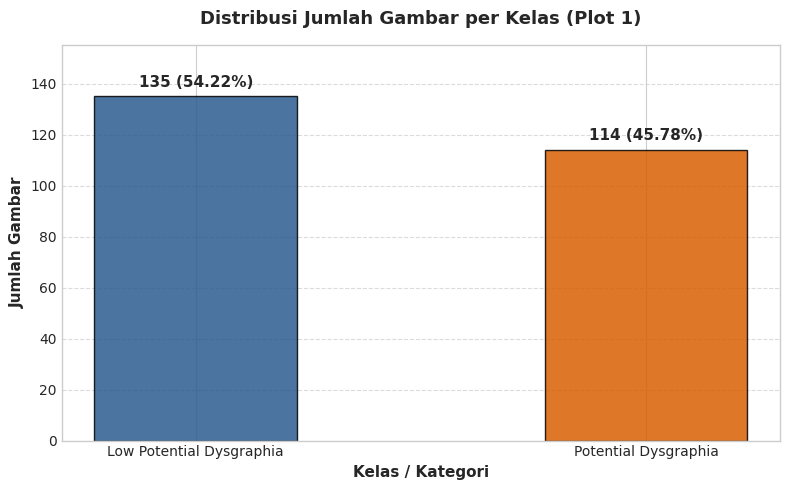

Rasio Distribusi Kelas: 1 : 1.18
[ANALISIS] Dataset relatif seimbang (Balanced). Tidak terdapat ketimpangan kelas yang signifikan.


In [5]:
# Filter data untuk hanya menyertakan citra yang valid
df_valid = df_dataset[df_dataset['is_valid_image']].copy()

# Tabel Distribusi Kelas
class_distribution = df_valid['label'].value_counts().reset_index()
class_distribution.columns = ['Kelas / Label', 'Jumlah Gambar']
class_distribution['Persentase (%)'] = (class_distribution['Jumlah Gambar'] / len(df_valid) * 100).round(2)

print("Tabel Distribusi Kelas:")
display(class_distribution)

# Visualisasi Bar Chart Distribusi Kelas (Plot 1)
fig, ax = plt.subplots(figsize=(8, 5))
palette = ['#2b5c8f', '#d95f02'] if len(class_distribution) == 2 else sns.color_palette('tab10', len(class_distribution))

bars = ax.bar(
    class_distribution['Kelas / Label'],
    class_distribution['Jumlah Gambar'],
    color=palette,
    width=0.45,
    edgecolor='black',
    alpha=0.85
)

# Menambahkan anotasi nilai dan persentase di atas setiap bar
for bar, pct in zip(bars, class_distribution['Persentase (%)']):
    height_val = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        height_val + (max(class_distribution['Jumlah Gambar']) * 0.02),
        f'{int(height_val)} ({pct}%)',
        ha='center', va='bottom', fontsize=11, fontweight='bold'
    )

ax.set_title('Distribusi Jumlah Gambar per Kelas (Plot 1)', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Kelas / Kategori', fontsize=11, fontweight='bold')
ax.set_ylabel('Jumlah Gambar', fontsize=11, fontweight='bold')
ax.set_ylim(0, max(class_distribution['Jumlah Gambar']) * 1.15)
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Evaluasi Rasio Keseimbangan Kelas
count_max = class_distribution['Jumlah Gambar'].max()
count_min = class_distribution['Jumlah Gambar'].min()
imbalance_ratio = round(count_max / count_min, 2) if count_min > 0 else 0

print(f"Rasio Distribusi Kelas: 1 : {imbalance_ratio}")
if imbalance_ratio <= 1.25:
    print("[ANALISIS] Dataset relatif seimbang (Balanced). Tidak terdapat ketimpangan kelas yang signifikan.")
elif imbalance_ratio <= 1.5:
    print("[ANALISIS] Dataset memiliki sedikit perbedaan jumlah antar kelas, namun masih dalam batas seimbang dan wajar.")
else:
    print("[ANALISIS] Terindikasi adanya Class Imbalance yang cukup tinggi. Perlu dipertimbangkan teknik penanganan imbalance pada tahap modeling.")


---
## 6. Visualisasi Sampel Gambar (*Sample Images*)
Menampilkan 5 contoh gambar tulisan tangan dari masing-masing kelas secara acak menggunakan `random_state = 42` agar hasil reproduktif.

Tahap ini murni menampilkan sampel asli tanpa manipulasi, filter, atau augmentasi.


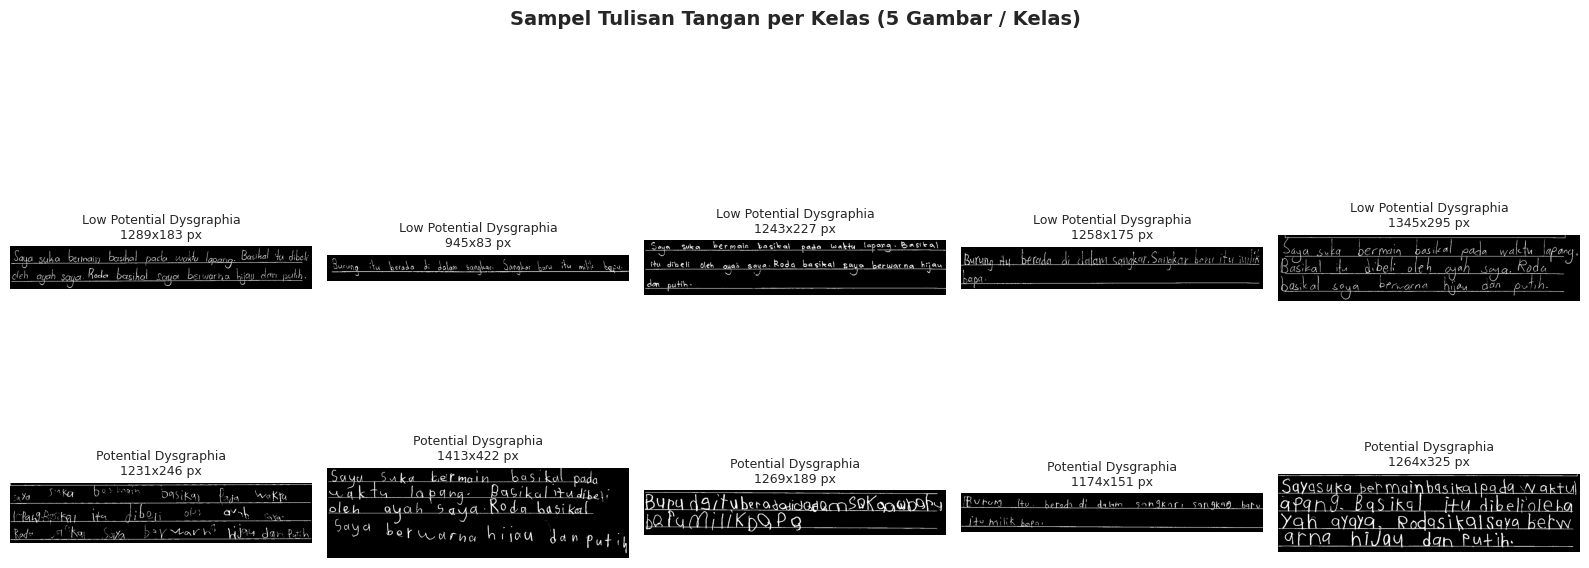

In [6]:
def display_sample_images(df, n_samples=5, seed=42):
    """
    Menampilkan grid sampel gambar untuk setiap kelas secara rapi.
    """
    unique_labels = sorted(df['label'].unique())
    n_rows = len(unique_labels)
    n_cols = n_samples
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3.2, n_rows * 3.5))
    
    if n_rows == 1:
        axes = np.array([axes])
        
    for row_idx, label in enumerate(unique_labels):
        subset = df[df['label'] == label]
        sampled = subset.sample(n=min(n_samples, len(subset)), random_state=seed)
        
        for col_idx, (_, row) in enumerate(sampled.iterrows()):
            ax = axes[row_idx, col_idx] if n_rows > 1 else axes[col_idx]
            try:
                with Image.open(row['filepath']) as img:
                    ax.imshow(img, cmap='gray' if img.mode in ('L', '1') else None)
                ax.set_title(f"{row['label']}\n{row['width']}x{row['height']} px", fontsize=9, fontweight='medium')
            except Exception as e:
                ax.text(0.5, 0.5, "Gagal membuka", ha='center', va='center')
                
            ax.axis('off')
            
    plt.suptitle("Sampel Tulisan Tangan per Kelas (5 Gambar / Kelas)", fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

display_sample_images(df_valid, n_samples=5, seed=RANDOM_STATE)


---
## 7. Analisis Properti Citra (*Image Properties*)
Menganalisis karakteristik teknis gambar:
- Dimensi: Lebar (*Width*) dan Tinggi (*Height*)
- Nilai: *min*, *max*, *mean*, *median*, dan *standar deviasi*
- *Color Mode* dan Jumlah *Channels*


In [7]:
# Statistik Deskriptif Dimensi Gambar
dim_stats = pd.DataFrame({
    'Width (px)': [
        df_valid['width'].min(),
        df_valid['width'].max(),
        df_valid['width'].mean(),
        df_valid['width'].median(),
        df_valid['width'].std()
    ],
    'Height (px)': [
        df_valid['height'].min(),
        df_valid['height'].max(),
        df_valid['height'].mean(),
        df_valid['height'].median(),
        df_valid['height'].std()
    ]
}, index=['min', 'max', 'mean', 'median', 'std dev']).round(2)

print("Tabel Statistik Dimensi Gambar (Width & Height):")
display(dim_stats)

# Analisis Keseragaman Resolusi
unique_resolutions = df_valid.groupby(['width', 'height']).size().reset_index(name='Jumlah Gambar')
print(f"\nJumlah kombinasi resolusi unik (Width x Height): {len(unique_resolutions)}")

if len(unique_resolutions) == 1:
    w_fixed, h_fixed = unique_resolutions.iloc[0]['width'], unique_resolutions.iloc[0]['height']
    print(f"[OBSERVASI] Ukuran gambar seragam sepenuhnya: seluruh gambar berukuran {w_fixed} x {h_fixed} piksel.")
else:
    print("[OBSERVASI] Ukuran gambar bervariasi. 5 Resolusi paling sering ditemukan:")
    display(unique_resolutions.sort_values(by='Jumlah Gambar', ascending=False).head(5))

# Distribusi Mode Warna & Kanal
mode_channel_df = df_valid.groupby(['mode', 'channels']).size().reset_index(name='Jumlah Gambar')
print("\nDistribusi Mode Warna (Color Mode) & Kanal:")
display(mode_channel_df)


Tabel Statistik Dimensi Gambar (Width & Height):


,Width (px),Height (px)
min,396.00,55.00
max,1434.00,448.00
mean,1090.59,173.94
median,1204.00,164.00
std dev,244.59,78.86



Jumlah kombinasi resolusi unik (Width x Height): 246
[OBSERVASI] Ukuran gambar bervariasi. 5 Resolusi paling sering ditemukan:


,width,height,Jumlah Gambar
148,1237,167,2
164,1250,165,2
198,1269,189,2
0,396,59,1
169,1250,255,1



Distribusi Mode Warna (Color Mode) & Kanal:


,mode,channels,Jumlah Gambar
0,L,1,249


---
## 8. Analisis Aspect Ratio
Rasio aspek (*Aspect Ratio*) dihitung dengan formula:
$$\text{Aspect Ratio} = \frac{\text{Width}}{\text{Height}}$$

**Tujuan**:
Mengetahui apakah gambar memiliki bentuk yang seragam (misal: kotak 1:1, landscape > 1, portrait < 1) atau terdapat variasi bentuk yang besar sehingga perlu strategi *resizing* / *padding* yang tepat sebelum masuk ke arsitektur CNN/Vision Model.


In [8]:
# Statistik Deskriptif Aspect Ratio
ar_stats = pd.DataFrame({
    'Metric': ['min aspect_ratio', 'max aspect_ratio', 'mean aspect_ratio', 'median aspect_ratio', 'std aspect_ratio'],
    'Value': [
        df_valid['aspect_ratio'].min(),
        df_valid['aspect_ratio'].max(),
        round(df_valid['aspect_ratio'].mean(), 4),
        round(df_valid['aspect_ratio'].median(), 4),
        round(df_valid['aspect_ratio'].std(), 4)
    ]
})

print("Tabel Statistik Aspect Ratio:")
display(ar_stats)

if df_valid['aspect_ratio'].min() == df_valid['aspect_ratio'].max():
    print(f"[OBSERVASI] Seluruh gambar memiliki aspect ratio yang persis sama ({df_valid['aspect_ratio'].iloc[0]}).")
else:
    print(f"[OBSERVASI] Sebagian besar gambar memiliki aspect ratio sekitar {df_valid['aspect_ratio'].median():.2f} "
          f"(rentang: {df_valid['aspect_ratio'].min():.2f} s.d. {df_valid['aspect_ratio'].max():.2f}).")


Tabel Statistik Aspect Ratio:


,Metric,Value
0,min aspect_ratio,3.0201
1,max aspect_ratio,14.2386
2,mean aspect_ratio,7.0419
3,median aspect_ratio,6.9490
4,std aspect_ratio,2.1867


[OBSERVASI] Sebagian besar gambar memiliki aspect ratio sekitar 6.95 (rentang: 3.02 s.d. 14.24).


---
## 9. Perbandingan Karakteristik Antar Kelas
Membandingkan *Width*, *Height*, dan *Aspect Ratio* antara kelas `Low Potential Dysgraphia` dan `Potential Dysgraphia` menggunakan Boxplot sederhana untuk melihat apakah terdapat perbedaan dimensi atau bias ukuran citra antar kelas.


Perbandingan Statistik Dimensi per Kelas:


width                     height                  \
                             mean  median  min   max    mean median min  max   
label                                                                          
Low Potential Dysgraphia  1020.22  1157.0  396  1377  156.02  159.0  55  360   
Potential Dysgraphia      1173.91  1231.0  700  1434  195.16  177.5  77  448   

                         aspect_ratio                      
                                 mean median   min    max  
label                                                      
Low Potential Dysgraphia         7.15   7.04  3.46  13.83  
Potential Dysgraphia             6.92   6.71  3.02  14.24

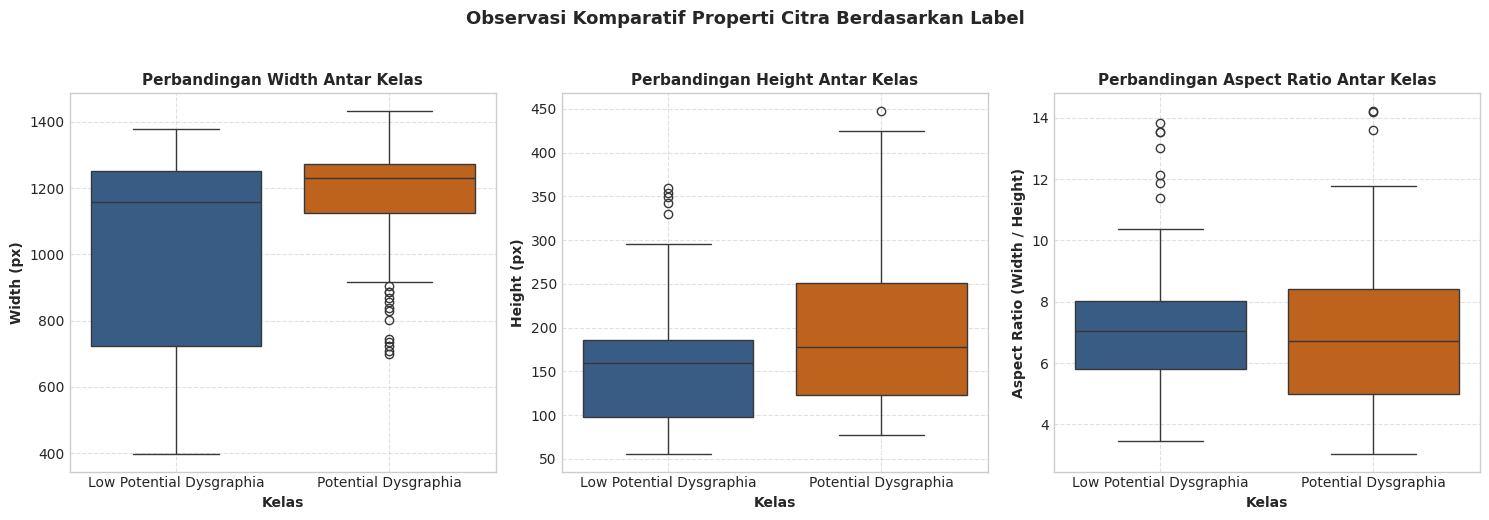

In [9]:
# Perbandingan Statistik Ringkas Antar Kelas
class_comparison = df_valid.groupby('label')[['width', 'height', 'aspect_ratio']].agg(
    ['mean', 'median', 'min', 'max']
).round(2)

print("Perbandingan Statistik Dimensi per Kelas:")
display(class_comparison)

# Visualisasi Boxplot Komparatif Antar Kelas
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
palette = ['#2b5c8f', '#d95f02']

# 1. Boxplot Width
sns.boxplot(x='label', y='width', data=df_valid, ax=axes[0], hue='label', palette=palette, legend=False)
axes[0].set_title('Perbandingan Width Antar Kelas', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Kelas', fontweight='bold')
axes[0].set_ylabel('Width (px)', fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. Boxplot Height
sns.boxplot(x='label', y='height', data=df_valid, ax=axes[1], hue='label', palette=palette, legend=False)
axes[1].set_title('Perbandingan Height Antar Kelas', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Kelas', fontweight='bold')
axes[1].set_ylabel('Height (px)', fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.6)

# 3. Boxplot Aspect Ratio
sns.boxplot(x='label', y='aspect_ratio', data=df_valid, ax=axes[2], hue='label', palette=palette, legend=False)
axes[2].set_title('Perbandingan Aspect Ratio Antar Kelas', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Kelas', fontweight='bold')
axes[2].set_ylabel('Aspect Ratio (Width / Height)', fontweight='bold')
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.suptitle('Observasi Komparatif Properti Citra Berdasarkan Label', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


---
## 10. Visualisasi Distribusi Utama
Kompilasi visualisasi inti yang berguna untuk menyajikan distribusi properti citra secara padat dan informatif:
* **Plot 2**: Distribusi *Width* (Histogram)
* **Plot 3**: Distribusi *Height* (Histogram)
* **Plot 4**: Distribusi *Aspect Ratio* (Histogram)
* **Plot 5**: Perbandingan *Aspect Ratio* Berdasarkan Kelas (Boxplot)


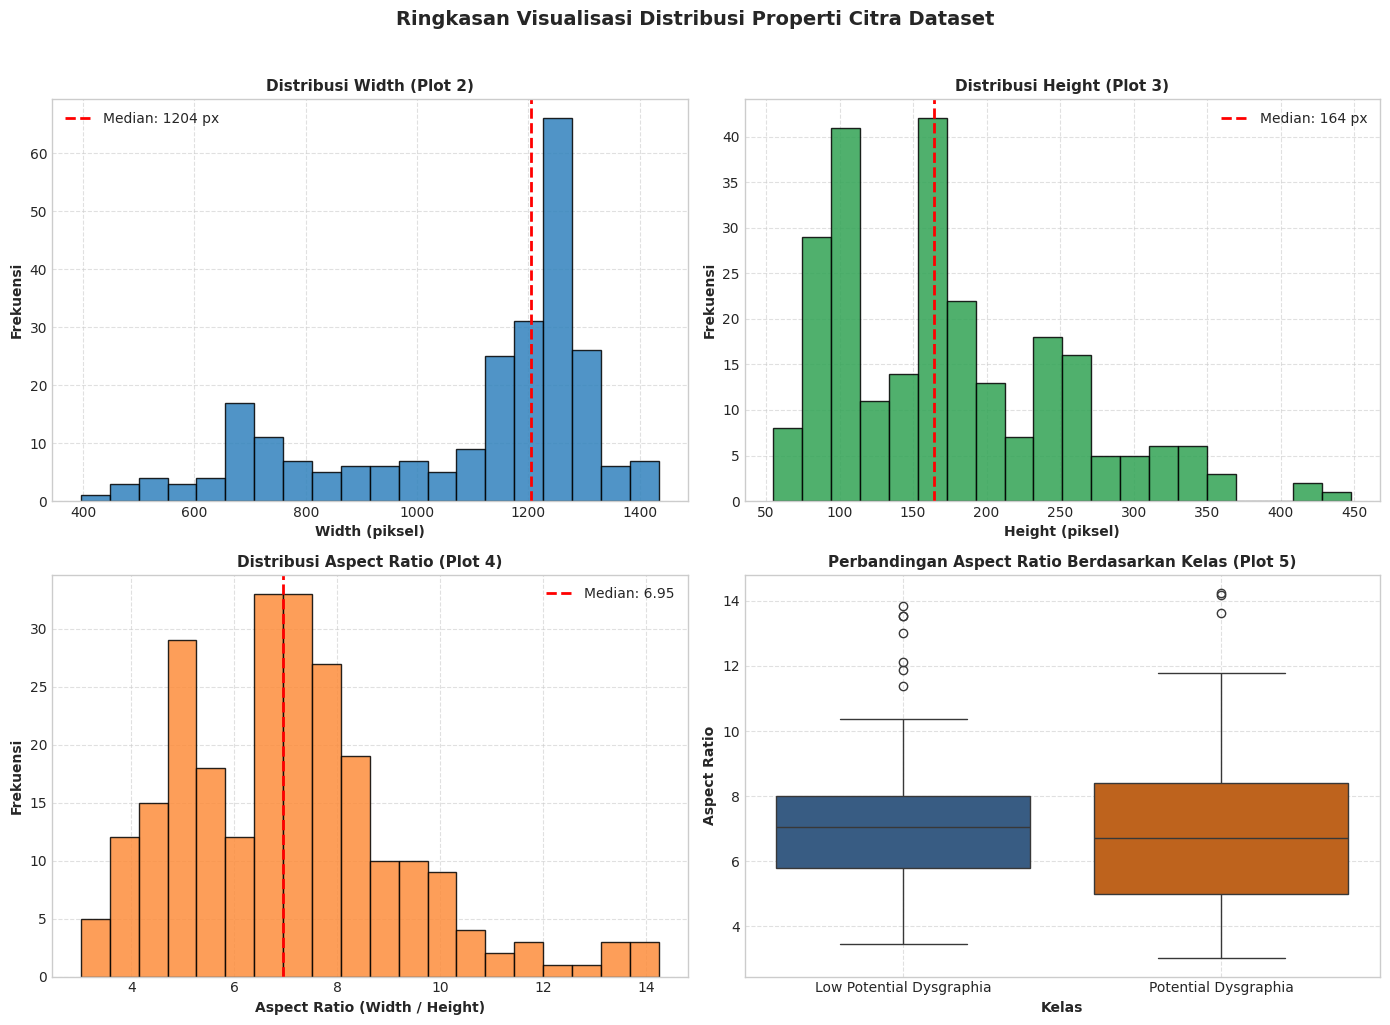

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 2: Histogram Width
w_median = df_valid['width'].median()
axes[0, 0].hist(df_valid['width'], bins=20, color='#3182bd', edgecolor='black', alpha=0.85)
axes[0, 0].axvline(w_median, color='red', linestyle='--', linewidth=2, label=f'Median: {w_median:.0f} px')
axes[0, 0].set_title('Distribusi Width (Plot 2)', fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel('Width (piksel)', fontweight='bold')
axes[0, 0].set_ylabel('Frekuensi', fontweight='bold')
axes[0, 0].legend(fontsize=10)
axes[0, 0].grid(True, linestyle='--', alpha=0.6)

# Plot 3: Histogram Height
h_median = df_valid['height'].median()
axes[0, 1].hist(df_valid['height'], bins=20, color='#31a354', edgecolor='black', alpha=0.85)
axes[0, 1].axvline(h_median, color='red', linestyle='--', linewidth=2, label=f'Median: {h_median:.0f} px')
axes[0, 1].set_title('Distribusi Height (Plot 3)', fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel('Height (piksel)', fontweight='bold')
axes[0, 1].set_ylabel('Frekuensi', fontweight='bold')
axes[0, 1].legend(fontsize=10)
axes[0, 1].grid(True, linestyle='--', alpha=0.6)

# Plot 4: Histogram Aspect Ratio
ar_median = df_valid['aspect_ratio'].median()
axes[1, 0].hist(df_valid['aspect_ratio'], bins=20, color='#fd8d3c', edgecolor='black', alpha=0.85)
axes[1, 0].axvline(ar_median, color='red', linestyle='--', linewidth=2, label=f'Median: {ar_median:.2f}')
axes[1, 0].set_title('Distribusi Aspect Ratio (Plot 4)', fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel('Aspect Ratio (Width / Height)', fontweight='bold')
axes[1, 0].set_ylabel('Frekuensi', fontweight='bold')
axes[1, 0].legend(fontsize=10)
axes[1, 0].grid(True, linestyle='--', alpha=0.6)

# Plot 5: Perbandingan Aspect Ratio berdasarkan Kelas
sns.boxplot(x='label', y='aspect_ratio', data=df_valid, ax=axes[1, 1], hue='label', palette=['#2b5c8f', '#d95f02'], legend=False)
axes[1, 1].set_title('Perbandingan Aspect Ratio Berdasarkan Kelas (Plot 5)', fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel('Kelas', fontweight='bold')
axes[1, 1].set_ylabel('Aspect Ratio', fontweight='bold')
axes[1, 1].grid(True, linestyle='--', alpha=0.6)

plt.suptitle('Ringkasan Visualisasi Distribusi Properti Citra Dataset', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
## 11. Pemeriksaan Duplikasi (*Duplicate / Filename Check*)
Pengecekan sederhana terhadap redundansi data:
1. **Duplicate Filepath**: Apakah ada path file yang persis sama terdata ganda.
2. **Duplicate Filename (Global)**: Apakah ada nama berkas yang sama di dalam seluruh dataset.
3. **Filename Overlap**: Apakah terdapat nama berkas identik yang muncul pada kelas yang berbeda.

> **Catatan**: Jika ditemukan kemungkinan duplikat, sistem menampilkan peringatan namun **tidak menghapus data secara otomatis**.


In [11]:
def check_dataset_duplicates(df):
    """
    Memeriksa duplikasi filepath dan nama berkas.
    """
    dup_filepaths = df.duplicated(subset=['filepath']).sum()
    dup_filenames_global = df.duplicated(subset=['filename'], keep=False).sum()
    
    # Filename yang muncul di lebih dari satu kelas
    class_per_filename = df.groupby('filename')['label'].nunique()
    overlap_filenames = class_per_filename[class_per_filename > 1].index.tolist()
    
    print("=" * 60)
    print("             HASIL PEMERIKSAAN DUPLIKASI")
    print("=" * 60)
    print(f"Duplikasi filepath                   : {dup_filepaths}")
    print(f"Berkas dengan nama sama (Global)     : {dup_filenames_global}")
    print(f"Nama berkas yang muncul di > 1 kelas : {len(overlap_filenames)}")
    print("-" * 60)
    
    if len(overlap_filenames) > 0:
        print("[WARNING] Ditemukan nama file yang sama pada lebih dari satu kelas:")
        display(df[df['filename'].isin(overlap_filenames)].sort_values(by='filename')[['filename', 'label', 'filepath']])
        print("💡 Catatan: File tidak dihapus secara otomatis. Silakan tinjau kembali sumber file.")
    else:
        print("[OK] Tidak ditemukan nama berkas yang tumpang tindih antar kelas.")
    print("=" * 60)

check_dataset_duplicates(df_dataset)


             HASIL PEMERIKSAAN DUPLIKASI
Duplikasi filepath                   : 0
Berkas dengan nama sama (Global)     : 0
Nama berkas yang muncul di > 1 kelas : 0
------------------------------------------------------------
[OK] Tidak ditemukan nama berkas yang tumpang tindih antar kelas.


---
## 12. Ringkasan EDA (*EDA Summary & Recommendation*)
Kesimpulan otomatis berdasarkan keseluruhan proses analisis data eksploratif di atas beserta rekomendasi langkah *preprocessing* sebelum memulai pemodelan AI.


In [12]:
def generate_eda_summary(df_all, df_clean):
    """
    Menghasilkan ringkasan terstruktur otomatis dari hasil Exploratory Data Analysis.
    """
    total_files = len(df_all)
    valid_count = len(df_clean)
    invalid_count = total_files - valid_count
    
    class_counts = df_clean['label'].value_counts().to_dict()
    
    # 1. Analisis Keseimbangan Kelas
    if len(class_counts) >= 2:
        c_max = max(class_counts.values())
        c_min = min(class_counts.values())
        imb_ratio = round(c_max / c_min, 2)
        if imb_ratio <= 1.25:
            dist_desc = f"Dataset relatif seimbang (balanced) dengan rasio 1 : {imb_ratio}. Tidak terdapat ketimpangan kelas yang besar."
        elif imb_ratio <= 1.5:
            dist_desc = f"Dataset memiliki sedikit perbedaan proporsi (rasio 1 : {imb_ratio}), namun masih dalam batas wajar."
        else:
            dist_desc = f"Terdapat indikasi Class Imbalance yang cukup tinggi (rasio 1 : {imb_ratio})."
    else:
        dist_desc = "Hanya terdeteksi 1 kelas."

    # 2. Analisis Resolusi
    n_unique_res = len(df_clean.groupby(['width', 'height']))
    if n_unique_res == 1:
        dim_desc = f"Ukuran gambar seragam ({df_clean['width'].iloc[0]}x{df_clean['height'].iloc[0]} piksel)."
    else:
        dim_desc = (
            f"Ukuran gambar memiliki variasi (terdapat {n_unique_res} kombinasi resolusi berbeda). "
            f"Lebar berkisar {df_clean['width'].min()} - {df_clean['width'].max()} px, "
            f"dan tinggi berkisar {df_clean['height'].min()} - {df_clean['height'].max()} px."
        )
        
    # 3. Analisis Aspect Ratio
    median_ar = df_clean['aspect_ratio'].median()
    min_ar = df_clean['aspect_ratio'].min()
    max_ar = df_clean['aspect_ratio'].max()
    ar_desc = f"Sebagian besar gambar memiliki aspect ratio sekitar {median_ar:.2f} (rentang: {min_ar:.2f} - {max_ar:.2f})."
    
    # 4. Kualitas Citra
    if invalid_count == 0:
        quality_desc = f"Seluruh gambar ({valid_count} citra) dapat dibuka dan diverifikasi dengan baik tanpa gambar corrupt."
    else:
        quality_desc = f"Terdapat {invalid_count} file yang tidak valid/rusak dan perlu dieliminasi sebelum pemodelan."

    print("=" * 70)
    print("                             EDA SUMMARY")
    print("=" * 70)
    print(f"Total images              : {total_files}")
    for cls_name, count in class_counts.items():
        pct = (count / valid_count * 100)
        print(f" - {cls_name:<24}: {count} ({pct:.1f}%)")
    print("-" * 70)
    
    print("\nClass distribution:")
    print(f"  {dist_desc}")
    
    print("\nImage quality:")
    print(f"  {quality_desc}")
    
    print("\nImage dimensions:")
    print(f"  {dim_desc}")
    
    print("\nAspect ratio:")
    print(f"  {ar_desc}")
    
    print("\nRecommendation & Next Steps:")
    print("  1. Image Resizing & Padding: Karena ukuran citra bervariasi, lakukan standarisasi resolusi")
    print("     (misal: 224x224 atau 128x128) dengan mempertahankan aspect ratio atau letterbox padding")
    print("     agar goresan tulisan tangan tidak mengalami distorsi proporsi.")
    print("  2. Grayscale & Contrast Normalization: Citra tulisan tangan berfokus pada goresan tinta;")
    print("     konversi ke Grayscale dan terapkan adaptive thresholding/Otsu binarization untuk")
    print("     menghilangkan variasi pencahayaan dan warna kertas latar belakang.")
    print("  3. Stratified Dataset Splitting: Lakukan pembagian data (Train/Validation/Test) dengan")
    print("     Stratified Split agar proporsi kedua kelas tetap konsisten di setiap subset.")
    print("  4. Kesiapan Data: DATASET SIAP DILANJUTKAN KE TAHAP PREPROCESSING & MODELING.")
    print("=" * 70)

generate_eda_summary(df_dataset, df_valid)


                             EDA SUMMARY
Total images              : 249
 - Low Potential Dysgraphia: 135 (54.2%)
 - Potential Dysgraphia    : 114 (45.8%)
----------------------------------------------------------------------

Class distribution:
  Dataset relatif seimbang (balanced) dengan rasio 1 : 1.18. Tidak terdapat ketimpangan kelas yang besar.

Image quality:
  Seluruh gambar (249 citra) dapat dibuka dan diverifikasi dengan baik tanpa gambar corrupt.

Image dimensions:
  Ukuran gambar memiliki variasi (terdapat 246 kombinasi resolusi berbeda). Lebar berkisar 396 - 1434 px, dan tinggi berkisar 55 - 448 px.

Aspect ratio:
  Sebagian besar gambar memiliki aspect ratio sekitar 6.95 (rentang: 3.02 - 14.24).

Recommendation & Next Steps:
  1. Image Resizing & Padding: Karena ukuran citra bervariasi, lakukan standarisasi resolusi
     (misal: 224x224 atau 128x128) dengan mempertahankan aspect ratio atau letterbox padding
     agar goresan tulisan tangan tidak mengalami distorsi propors